# SEG01 Classical Segmentation Foundations

**Course module:** Classical crack segmentation using image processing baselines  
**Dataset:** Kaggle Crack Segmentation Dataset  
**Dataset link:** https://www.kaggle.com/datasets/lakshaymiddha/crack-segmentation-dataset/data

**Course Instructor**  
Dr. Md Rifat Ahmmad Rashid  
Associate Professor  
East West University Bangladesh

## Learning goals

1. Build one repeatable classical segmentation workflow for crack images and binary masks.
2. Compare thresholding, edge-based, region-based, morphology-based, and watershed methods on the same dataset.
3. Measure segmentation quality using IoU, Dice, precision, recall, runtime, and boundary overlays.
4. Analyze failure cases involving weak cracks, noisy surfaces, and noncrack images.
5. Batch-create binary crack masks from image folders using the selected classical baseline.

## Key concepts covered

1. Global, Otsu, adaptive, and multi-Otsu thresholding.
2. Sobel, Canny, Laplacian of Gaussian, contour extraction, and watershed boundaries.
3. Seeded region growing, connected components, distance transforms, and marker generation.
4. Morphological opening, closing, gradient, skeletonization, and shape descriptors.
5. Binary segmentation evaluation under foreground/background imbalance.

## 1. Kaggle setup and dataset mounting

In a Kaggle notebook, add the dataset from the right-side **Add Data** panel.  
The notebook will automatically search common Kaggle input locations, including the path specified below:

```text
/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/images
```

Kaggle often mounts datasets using a shorter path such as:

```text
/kaggle/input/crack-segmentation-dataset/crack_segmentation_dataset
```

The discovery code below checks both patterns and also searches inside `/kaggle/input`.

In [1]:
import os
import re
import time
import random
from pathlib import Path

# tqdm gives notebook-friendly progress bars for long loops in Kaggle.
try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(iterable=None, **kwargs):
        return iterable if iterable is not None else []

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from skimage.filters import threshold_multiotsu
from skimage.morphology import remove_small_objects, skeletonize
from skimage.measure import label, regionprops

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

pd.set_option("display.max_colwidth", 120)

# Central configuration block: adjust limits and output folders here before running the full notebook.
CONFIG = {
    "dataset_hint": "/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/images",
    "eval_max_images": 80,
    "preview_max_images": 6,
    "min_object_area": 25,
    "mask_threshold": 127,
    "generated_mask_dir": "/kaggle/working/seg01_generated_masks",
    "overlay_dir": "/kaggle/working/seg01_generated_overlays",
}

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

print("SEG01 Classical Segmentation Foundations")
print("Instructor: Dr. Md Rifat Ahmmad Rashid")
print("Institution: East West University Bangladesh")

def show_progress(iterable, desc=None, total=None, leave=True, unit="item"):
    """Return a tqdm progress iterator; keeps loops readable in notebook cells."""
    return tqdm(iterable, desc=desc, total=total, leave=leave, unit=unit)


SEG01 Classical Segmentation Foundations
Instructor: Dr. Md Rifat Ahmmad Rashid
Institution: East West University Bangladesh


## 2. Dataset discovery

The dataset may contain folders named `images`, `masks`, `train`, `test`, or similar variants.  
This section recursively searches the dataset root, separates image files from mask files, and pairs them using normalized file stems.

In [2]:
def normalize_stem(path_or_stem):
    """Normalize a filename stem so image and mask names can be matched."""
    stem = Path(str(path_or_stem)).stem.lower()
    replacements = [
        "_mask", "-mask", " mask",
        "_masks", "-masks",
        "_gt", "-gt", "_groundtruth", "-groundtruth",
        "_label", "-label", "_labels", "-labels",
        "_seg", "-seg", "_segmentation", "-segmentation",
        "_binary", "-binary"
    ]
    for token in replacements:
        stem = stem.replace(token, "")
    stem = re.sub(r"[^a-z0-9]+", "", stem)
    return stem


def has_mask_indicator(path):
    """Return True if a path likely belongs to a mask/label/ground-truth directory or file."""
    p = Path(path)
    parts = [part.lower() for part in p.parts]
    name = p.stem.lower()
    mask_tokens = {"mask", "masks", "label", "labels", "gt", "groundtruth", "ground_truth", "annotations", "annotation"}

    if any(part in mask_tokens for part in parts):
        return True

    filename_tokens = ["_mask", "-mask", "mask_", "_gt", "-gt", "_label", "-label", "_seg", "-seg"]
    return any(tok in name for tok in filename_tokens)


def candidate_dataset_roots():
    """Build a list of possible dataset roots."""
    hint = Path(CONFIG["dataset_hint"])
    candidates = []

    if hint.exists():
        candidates.append(hint if hint.name.lower() != "images" else hint.parent)

    manual_candidates = [
        "/kaggle/input/crack-segmentation-dataset/crack_segmentation_dataset",
        "/kaggle/input/crack-segmentation-dataset",
        "/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset",
        "/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset",
        "/kaggle/input",
        "./crack_segmentation_dataset",
        "./crack-segmentation-dataset",
        "."
    ]

    for item in manual_candidates:
        p = Path(item)
        if p.exists():
            candidates.append(p)

    input_root = Path("/kaggle/input")
    if input_root.exists():
        # Scan Kaggle input folders once and collect likely dataset roots.
        for p in show_progress(input_root.rglob("*"), desc="Scanning /kaggle/input", leave=False, unit="path"):
            if p.is_dir() and ("crack" in p.name.lower() or p.name.lower() in {"images", "masks"}):
                candidates.append(p if p.name.lower() not in {"images", "masks"} else p.parent)

    unique = []
    seen = set()
    for p in candidates:
        rp = str(p.resolve())
        if rp not in seen:
            unique.append(p.resolve())
            seen.add(rp)
    return unique


def discover_files(root):
    """Recursively scan a root folder and separate ordinary images from mask-like files."""
    root = Path(root)
    all_files = []

    # The progress bar is useful on Kaggle datasets with many nested files.
    for p in show_progress(root.rglob("*"), desc=f"Scanning files: {root.name}", leave=False, unit="file"):
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS:
            all_files.append(p)

    image_files, mask_files = [], []
    for p in show_progress(all_files, desc="Separating images and masks", leave=False, unit="file"):
        if has_mask_indicator(p):
            mask_files.append(p)
        else:
            image_files.append(p)

    return image_files, mask_files


def infer_split(path):
    parts = [part.lower() for part in Path(path).parts]
    if "train" in parts or "training" in parts:
        return "train"
    if "valid" in parts or "val" in parts or "validation" in parts:
        return "valid"
    if "test" in parts or "testing" in parts:
        return "test"
    return "unspecified"


def pair_images_and_masks(image_files, mask_files):
    """Match images with masks using normalized stems rather than folder-specific assumptions."""
    mask_lookup = {}

    # Build a lookup table from several normalized mask-name variants.
    for m in show_progress(mask_files, desc="Indexing masks", leave=False, unit="mask"):
        keys = {normalize_stem(m.stem), re.sub(r"[^a-z0-9]+", "", m.stem.lower())}
        for key in keys:
            if key and key not in mask_lookup:
                mask_lookup[key] = m

    rows = []
    for img in show_progress(image_files, desc="Pairing images with masks", leave=False, unit="image"):
        key = normalize_stem(img.stem)
        mask = mask_lookup.get(key)
        rows.append({
            "split": infer_split(img),
            "image_path": str(img),
            "mask_path": str(mask) if mask is not None else None,
            "image_name": img.name,
            "pair_key": key,
        })
    return pd.DataFrame(rows)


roots = candidate_dataset_roots()
print("Candidate roots checked:")
for r in roots[:12]:
    print("  ", r)

best_root = None
best_df = pd.DataFrame()
best_counts = (0, 0, 0)

for root in roots:
    image_files, mask_files = discover_files(root)
    if len(image_files) == 0:
        continue

    df_try = pair_images_and_masks(image_files, mask_files)
    paired_count = df_try["mask_path"].notna().sum()
    score = (paired_count, len(image_files), len(mask_files))

    if score > best_counts:
        best_counts = score
        best_root = root
        best_df = df_try.copy()

if best_root is None or len(best_df) == 0:
    raise FileNotFoundError(
        "No image files were found. Add the Kaggle dataset to the notebook, then rerun this cell."
    )

DATASET_ROOT = Path(best_root)
df_pairs = best_df.sort_values(["split", "image_name"]).reset_index(drop=True)

print(f"\nSelected dataset root: {DATASET_ROOT}")
print(f"Discovered images: {len(df_pairs)}")
print(f"Paired masks: {df_pairs['mask_path'].notna().sum()}")
print(f"Unpaired images: {df_pairs['mask_path'].isna().sum()}")

display(df_pairs.head(10))
display(df_pairs.groupby("split").agg(images=("image_path", "count"), masks=("mask_path", lambda s: s.notna().sum())))

Scanning /kaggle/input: 0path [00:00, ?path/s]

Candidate roots checked:
   /kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset
   /kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset
   /kaggle/input
   /kaggle/working
   /kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/test
   /kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/train


Scanning files: crack_segmentation_dataset: 0file [00:00, ?file/s]

Separating images and masks:   0%|          | 0/45192 [00:00<?, ?file/s]

Indexing masks:   0%|          | 0/22626 [00:00<?, ?mask/s]

Pairing images with masks:   0%|          | 0/22566 [00:00<?, ?image/s]

... (17 outputs left out)

Pairing images with masks:   0%|          | 0/9588 [00:00<?, ?image/s]


Selected dataset root: /kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset
Discovered images: 22566
Paired masks: 22566
Unpaired images: 0


,split,image_path,mask_path,image_name,pair_key
0,test,/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/test/images/CFD_001.jpg,/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/masks/CFD_001.jpg,CFD_001.jpg,cfd001
1,test,/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/test/images/CFD_007.jpg,/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/masks/CFD_007.jpg,CFD_007.jpg,cfd007
2,test,/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/test/images/CFD_011.jpg,/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/masks/CFD_011.jpg,CFD_011.jpg,cfd011
3,test,/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/test/images/CFD_013.jpg,/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/masks/CFD_013.jpg,CFD_013.jpg,cfd013
4,test,/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/test/images/CFD_014.jpg,/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/masks/CFD_014.jpg,CFD_014.jpg,cfd014
5,test,/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/test/images/CFD_019.jpg,/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/masks/CFD_019.jpg,CFD_019.jpg,cfd019
6,test,/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/test/images/CFD_037.jpg,/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/masks/CFD_037.jpg,CFD_037.jpg,cfd037
7,test,/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/test/images/CFD_040.jpg,/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/masks/CFD_040.jpg,CFD_040.jpg,cfd040
8,test,/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/test/images/CFD_047.jpg,/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/masks/CFD_047.jpg,CFD_047.jpg,cfd047
9,test,/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/test/images/CFD_070.jpg,/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/masks/CFD_070.jpg,CFD_070.jpg,cfd070


,images,masks
split,,
test,1695,1695
train,9588,9588
unspecified,11283,11283


## 3. Image, mask, histogram, and overlay utilities

The mask is treated as foreground when pixel values are greater than 127.  
If a mask resolution differs from the image resolution, it is resized using nearest-neighbor interpolation.

In [3]:
def read_rgb(path):
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError(f"Could not read image: {path}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def read_gray(path):
    gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if gray is None:
        raise ValueError(f"Could not read grayscale image: {path}")
    return gray


def read_mask(mask_path, target_shape=None):
    if mask_path is None or pd.isna(mask_path):
        return None
    mask = read_gray(mask_path)
    if target_shape is not None and mask.shape[:2] != target_shape[:2]:
        mask = cv2.resize(mask, (target_shape[1], target_shape[0]), interpolation=cv2.INTER_NEAREST)
    return (mask > CONFIG["mask_threshold"]).astype(np.uint8)


def rgb_to_gray(rgb):
    return cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)


def normalize_uint8(arr):
    arr = arr.astype(np.float32)
    mn, mx = arr.min(), arr.max()
    if mx - mn < 1e-8:
        return np.zeros_like(arr, dtype=np.uint8)
    return ((arr - mn) / (mx - mn) * 255).astype(np.uint8)


def make_overlay(rgb, mask, color=(255, 0, 0), alpha=0.45):
    overlay = rgb.copy()
    if mask is None:
        return overlay
    mask_bool = mask.astype(bool)
    color_arr = np.array(color, dtype=np.uint8)
    overlay[mask_bool] = (alpha * color_arr + (1 - alpha) * overlay[mask_bool]).astype(np.uint8)
    return overlay


def boundary_overlay(rgb, gt_mask=None, pred_mask=None):
    """Green: GT boundary. Red: prediction boundary. Yellow: overlap."""
    canvas = rgb.copy()

    def boundary(mask):
        if mask is None:
            return np.zeros(rgb.shape[:2], dtype=bool)
        mask_u8 = mask.astype(np.uint8)
        kernel = np.ones((3, 3), np.uint8)
        grad = cv2.morphologyEx(mask_u8, cv2.MORPH_GRADIENT, kernel)
        return grad.astype(bool)

    gt_b = boundary(gt_mask)
    pr_b = boundary(pred_mask)

    canvas[gt_b] = [0, 255, 0]
    canvas[pr_b] = [255, 0, 0]
    canvas[gt_b & pr_b] = [255, 255, 0]
    return canvas


def error_overlay(rgb, gt_mask, pred_mask):
    """Green: true positive, Red: false positive, Blue: false negative."""
    canvas = rgb.copy()
    gt = gt_mask.astype(bool)
    pr = pred_mask.astype(bool)
    tp = gt & pr
    fp = (~gt) & pr
    fn = gt & (~pr)

    canvas[tp] = (0.45 * np.array([0, 255, 0]) + 0.55 * canvas[tp]).astype(np.uint8)
    canvas[fp] = (0.55 * np.array([255, 0, 0]) + 0.45 * canvas[fp]).astype(np.uint8)
    canvas[fn] = (0.55 * np.array([0, 0, 255]) + 0.45 * canvas[fn]).astype(np.uint8)
    return canvas


def plot_image_mask_hist_overlay(rows, title="Sample image, mask, histogram, and overlay"):
    n = len(rows)
    fig, axes = plt.subplots(n, 4, figsize=(16, 4 * n))
    if n == 1:
        axes = np.expand_dims(axes, axis=0)

    for i, row in enumerate(rows):
        rgb = read_rgb(row["image_path"])
        gray = rgb_to_gray(rgb)
        mask = read_mask(row["mask_path"], target_shape=gray.shape) if row["mask_path"] else None

        axes[i, 0].imshow(rgb)
        axes[i, 0].set_title("Image")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(mask if mask is not None else np.zeros_like(gray), cmap="gray")
        axes[i, 1].set_title("Mask")
        axes[i, 1].axis("off")

        axes[i, 2].hist(gray.ravel(), bins=64)
        axes[i, 2].set_title("Grayscale histogram")
        axes[i, 2].set_xlabel("Intensity")
        axes[i, 2].set_ylabel("Frequency")

        axes[i, 3].imshow(make_overlay(rgb, mask))
        axes[i, 3].set_title("Mask overlay")
        axes[i, 3].axis("off")

    fig.suptitle(title, fontsize=14, y=1.01)
    plt.tight_layout()
    plt.show()

## 4. Visualize crack and noncrack examples

This section uses the available binary masks to identify positive crack samples and likely noncrack samples.  
If the dataset contains no empty masks, the noncrack section will simply use low-foreground samples.

Computing foreground ratios:   0%|          | 0/22566 [00:00<?, ?image/s]

Foreground ratio summary:


count    22566.000000
mean         0.034925
std          0.036693
min          0.000000
25%          0.012992
50%          0.025156
75%          0.043900
max          0.419478
Name: foreground_ratio, dtype: float64

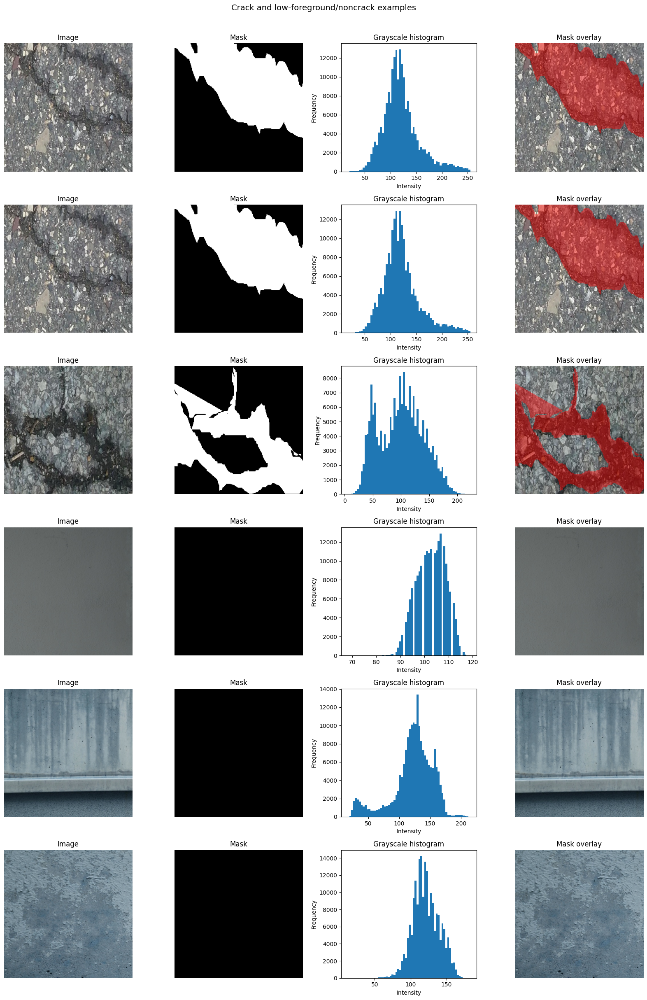

In [4]:
paired_df = df_pairs[df_pairs["mask_path"].notna()].copy().reset_index(drop=True)

if len(paired_df) == 0:
    print("No provided masks were found. Visualization will use images only.")
    sample_rows = df_pairs.sample(min(4, len(df_pairs)), random_state=SEED).to_dict("records")
    plot_image_mask_hist_overlay(sample_rows, title="Image-only samples")
else:
    foreground_ratios = []
    # Foreground ratio helps select both strong-crack and weak/noncrack examples.
    for _, row in show_progress(paired_df.iterrows(), total=len(paired_df), desc="Computing foreground ratios", unit="image"):

        rgb = read_rgb(row["image_path"])
        gray = rgb_to_gray(rgb)
        mask = read_mask(row["mask_path"], target_shape=gray.shape)
        foreground_ratios.append(mask.mean())

    paired_df["foreground_ratio"] = foreground_ratios

    crack_df = paired_df[paired_df["foreground_ratio"] > 0].sort_values("foreground_ratio", ascending=False)
    noncrack_df = paired_df[paired_df["foreground_ratio"] == 0]

    if len(noncrack_df) == 0:
        noncrack_df = paired_df.sort_values("foreground_ratio", ascending=True).head(3)

    selected = []
    selected += crack_df.head(3).to_dict("records")
    selected += noncrack_df.head(3).to_dict("records")
    selected = selected[:CONFIG["preview_max_images"]]

    print("Foreground ratio summary:")
    display(paired_df["foreground_ratio"].describe())

    plot_image_mask_hist_overlay(selected, title="Crack and low-foreground/noncrack examples")

## 5. Shared preprocessing and post-processing

The crack foreground is usually darker than the road or concrete background.  
Most baselines therefore start from grayscale contrast enhancement and then detect dark, thin structures.

In [5]:
def preprocess_gray(rgb, blur=True, clahe=True):
    gray = rgb_to_gray(rgb)
    if clahe:
        enhancer = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        gray = enhancer.apply(gray)
    if blur:
        gray = cv2.GaussianBlur(gray, (3, 3), 0)
    return gray


def postprocess_binary(mask, min_area=None, close_kernel=3, open_kernel=0, dilate_iter=0):
    """Clean a binary prediction mask using morphology and small-object removal."""
    if min_area is None:
        min_area = CONFIG["min_object_area"]

    mask = (mask > 0).astype(np.uint8)

    if open_kernel and open_kernel > 0:
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (open_kernel, open_kernel))
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

    if close_kernel and close_kernel > 0:
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (close_kernel, close_kernel))
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

    if min_area and min_area > 0:
        mask_bool = remove_small_objects(mask.astype(bool), min_size=min_area)
        mask = mask_bool.astype(np.uint8)

    if dilate_iter and dilate_iter > 0:
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
        mask = cv2.dilate(mask, kernel, iterations=dilate_iter)

    return mask.astype(np.uint8)


def fill_from_contours(edge_mask, min_area=10):
    """Convert an edge map into a region-like mask by closing and contour filling."""
    mask = (edge_mask > 0).astype(np.uint8)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
    closed = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=1)
    contours, _ = cv2.findContours((closed * 255).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    filled = np.zeros_like(mask, dtype=np.uint8)
    for cnt in contours:
        if cv2.contourArea(cnt) >= min_area:
            cv2.drawContours(filled, [cnt], -1, color=1, thickness=cv2.FILLED)
    return filled


def auto_canny(gray, sigma=0.33):
    v = np.median(gray)
    lower = int(max(0, (1.0 - sigma) * v))
    upper = int(min(255, (1.0 + sigma) * v))
    edges = cv2.Canny(gray, lower, upper)
    return (edges > 0).astype(np.uint8)


def ensure_same_shape(mask, shape):
    if mask.shape[:2] != shape[:2]:
        mask = cv2.resize(mask.astype(np.uint8), (shape[1], shape[0]), interpolation=cv2.INTER_NEAREST)
    return (mask > 0).astype(np.uint8)

## 6. Thresholding baselines

The thresholding group includes global thresholding, Otsu thresholding, adaptive thresholding, and multi-Otsu thresholding.

In [6]:
def baseline_global_threshold(rgb):
    gray = preprocess_gray(rgb)
    threshold_value = float(gray.mean() - 0.25 * gray.std())
    pred = (gray < threshold_value).astype(np.uint8)
    return postprocess_binary(pred, close_kernel=3, open_kernel=0, dilate_iter=1)


def baseline_otsu_threshold(rgb):
    gray = preprocess_gray(rgb)
    t, _ = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    pred = (gray < t).astype(np.uint8)
    return postprocess_binary(pred, close_kernel=3, open_kernel=0, dilate_iter=1)


def baseline_adaptive_threshold(rgb):
    gray = preprocess_gray(rgb)
    block_size = 35
    c_value = 5
    pred = cv2.adaptiveThreshold(
        gray, 1, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, block_size, c_value
    )
    return postprocess_binary(pred, close_kernel=3, open_kernel=0, dilate_iter=1)


def baseline_multiotsu_threshold(rgb):
    gray = preprocess_gray(rgb)
    try:
        thresholds = threshold_multiotsu(gray, classes=3)
        pred = (gray <= thresholds[0]).astype(np.uint8)
    except ValueError:
        pred = baseline_otsu_threshold(rgb)
    return postprocess_binary(pred, close_kernel=3, open_kernel=0, dilate_iter=1)

## 7. Edge, contour, and LoG baselines

This group identifies crack boundaries or thin discontinuities using gradients and edge detectors.

In [7]:
def baseline_sobel_edges(rgb):
    gray = preprocess_gray(rgb)
    sx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
    sy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
    mag = normalize_uint8(np.sqrt(sx ** 2 + sy ** 2))
    t, _ = cv2.threshold(mag, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    edges = (mag > t).astype(np.uint8)
    pred = fill_from_contours(edges, min_area=5)
    return postprocess_binary(pred, close_kernel=3, open_kernel=0, dilate_iter=1)


def baseline_canny_contours(rgb):
    gray = preprocess_gray(rgb)
    edges = auto_canny(gray)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
    edges = cv2.dilate(edges, kernel, iterations=1)
    pred = fill_from_contours(edges, min_area=5)
    return postprocess_binary(pred, close_kernel=3, open_kernel=0, dilate_iter=1)


def baseline_log_edges(rgb):
    gray = preprocess_gray(rgb)
    smooth = cv2.GaussianBlur(gray, (5, 5), 1.2)
    log = cv2.Laplacian(smooth, cv2.CV_32F, ksize=3)
    log_abs = normalize_uint8(np.abs(log))
    t, _ = cv2.threshold(log_abs, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    pred = (log_abs > t).astype(np.uint8)
    return postprocess_binary(pred, close_kernel=3, open_kernel=0, dilate_iter=1)

## 8. Region, connected-component, morphology, skeleton, and watershed baselines

This group uses spatial connectedness, shape filtering, morphological operators, and marker-based watershed segmentation.

In [8]:
def baseline_seeded_region_growing(rgb):
    gray = preprocess_gray(rgb)
    p10 = np.percentile(gray, 10)
    p35 = np.percentile(gray, 35)

    seeds = gray <= p10
    candidate = gray <= p35

    cc, num = label(candidate, connectivity=2, return_num=True)
    keep_labels = np.unique(cc[seeds])
    keep_labels = keep_labels[keep_labels != 0]

    pred = np.isin(cc, keep_labels).astype(np.uint8)
    return postprocess_binary(pred, close_kernel=3, open_kernel=0, dilate_iter=1)


def baseline_connected_components_shape(rgb):
    base = baseline_adaptive_threshold(rgb)

    labeled = label(base.astype(bool), connectivity=2)
    pred = np.zeros_like(base, dtype=np.uint8)

    for prop in regionprops(labeled):
        area = prop.area
        if area < CONFIG["min_object_area"]:
            continue

        major = prop.major_axis_length
        minor = prop.minor_axis_length
        eccentricity = prop.eccentricity
        solidity = prop.solidity if prop.solidity is not None else 1.0
        elongation = major / (minor + 1e-6)

        keep = (
            eccentricity >= 0.80
            or elongation >= 3.0
            or solidity <= 0.65
            or area >= 250
        )
        if keep:
            pred[labeled == prop.label] = 1

    return postprocess_binary(pred, close_kernel=3, open_kernel=0, dilate_iter=1)


def baseline_morphology_open_close(rgb):
    pred = baseline_adaptive_threshold(rgb)
    kernel_line_h = cv2.getStructuringElement(cv2.MORPH_RECT, (7, 1))
    kernel_line_v = cv2.getStructuringElement(cv2.MORPH_RECT, (1, 7))
    h = cv2.morphologyEx(pred, cv2.MORPH_CLOSE, kernel_line_h)
    v = cv2.morphologyEx(pred, cv2.MORPH_CLOSE, kernel_line_v)
    merged = np.maximum(h, v)
    return postprocess_binary(merged, close_kernel=3, open_kernel=0, dilate_iter=1)


def baseline_morphological_gradient(rgb):
    gray = preprocess_gray(rgb)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
    grad = cv2.morphologyEx(gray, cv2.MORPH_GRADIENT, kernel)
    t, _ = cv2.threshold(grad, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    pred = (grad > t).astype(np.uint8)
    return postprocess_binary(pred, close_kernel=3, open_kernel=0, dilate_iter=1)


def baseline_skeletonized_adaptive(rgb):
    base = baseline_adaptive_threshold(rgb)
    skel = skeletonize(base.astype(bool)).astype(np.uint8)
    return postprocess_binary(skel, close_kernel=0, open_kernel=0, min_area=0, dilate_iter=1)


def baseline_watershed_markers(rgb):
    gray = preprocess_gray(rgb)
    candidate = baseline_adaptive_threshold(rgb)

    if candidate.sum() == 0:
        return candidate.astype(np.uint8)

    kernel = np.ones((3, 3), np.uint8)
    sure_bg = cv2.dilate(candidate.astype(np.uint8), kernel, iterations=2)

    dist = cv2.distanceTransform(candidate.astype(np.uint8), cv2.DIST_L2, 5)
    if dist.max() <= 0:
        return candidate.astype(np.uint8)

    sure_fg = (dist > 0.25 * dist.max()).astype(np.uint8)
    unknown = cv2.subtract(sure_bg, sure_fg)

    num_markers, markers = cv2.connectedComponents(sure_fg)
    markers = markers + 1
    markers[unknown == 1] = 0

    rgb_for_ws = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)
    ws = cv2.watershed(rgb_for_ws, markers.astype(np.int32))

    pred = (ws > 1).astype(np.uint8)
    pred = np.logical_or(pred, candidate.astype(bool)).astype(np.uint8)
    return postprocess_binary(pred, close_kernel=3, open_kernel=0, dilate_iter=0)

## 9. Register all baselines

The dictionary below controls which methods are evaluated and displayed.  
You may comment out slower or weaker methods when running quick classroom demonstrations.

In [9]:
BASELINES = {
    "global_threshold": baseline_global_threshold,
    "otsu_threshold": baseline_otsu_threshold,
    "adaptive_threshold": baseline_adaptive_threshold,
    "multiotsu_threshold": baseline_multiotsu_threshold,
    "sobel_edges": baseline_sobel_edges,
    "canny_contours": baseline_canny_contours,
    "log_edges": baseline_log_edges,
    "seeded_region_growing": baseline_seeded_region_growing,
    "connected_components_shape": baseline_connected_components_shape,
    "morphology_open_close": baseline_morphology_open_close,
    "morphological_gradient": baseline_morphological_gradient,
    "skeletonized_adaptive": baseline_skeletonized_adaptive,
    "watershed_markers": baseline_watershed_markers,
}

list(BASELINES.keys())

['global_threshold',
 'otsu_threshold',
 'adaptive_threshold',
 'multiotsu_threshold',
 'sobel_edges',
 'canny_contours',
 'log_edges',
 'seeded_region_growing',
 'connected_components_shape',
 'morphology_open_close',
 'morphological_gradient',
 'skeletonized_adaptive',
 'watershed_markers']

## 10. Side-by-side qualitative comparison

The next cell runs all registered baselines on one selected example.  
For a classroom session, change `sample_index` to show how each method behaves on different crack textures.

Selected image: CRACK500_20160328_153813_1921_1081.jpg


Running baseline methods:   0%|          | 0/13 [00:00<?, ?method/s]

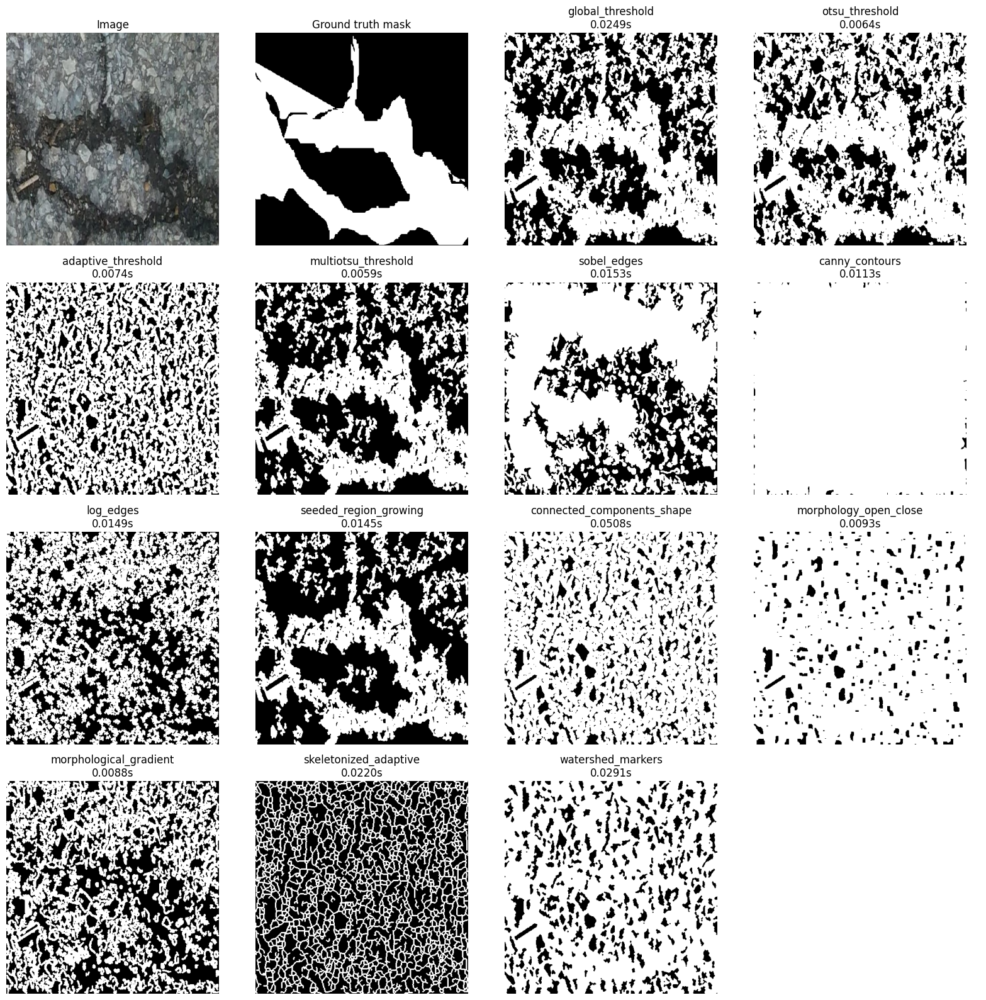

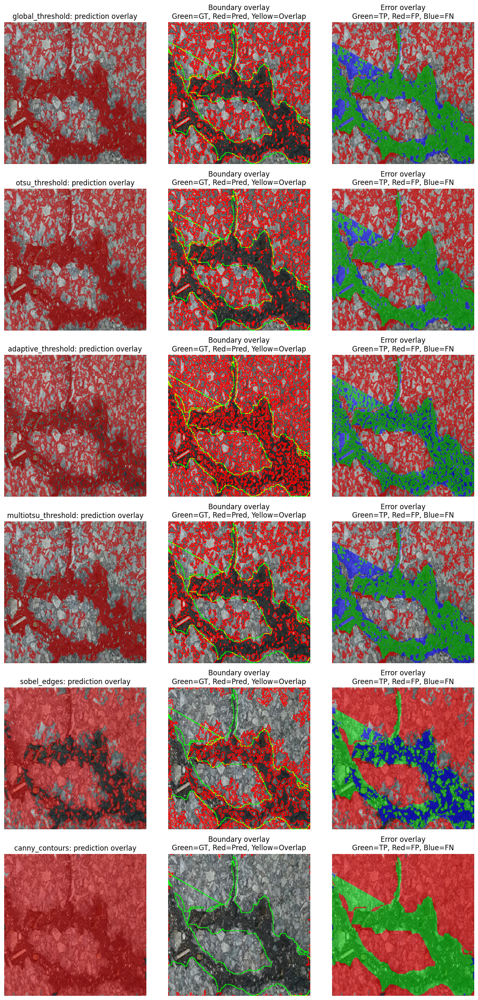

In [10]:
def plot_baseline_outputs(row, baselines=BASELINES):
    rgb = read_rgb(row["image_path"])
    gray = rgb_to_gray(rgb)
    gt = read_mask(row["mask_path"], target_shape=gray.shape) if row.get("mask_path") else None

    outputs = {}
    runtimes = {}
    # Run every registered method on the same sample for a fair visual comparison.
    for name, fn in show_progress(baselines.items(), total=len(baselines), desc="Running baseline methods", leave=False, unit="method"):
        start = time.perf_counter()
        pred = fn(rgb)
        elapsed = time.perf_counter() - start
        outputs[name] = ensure_same_shape(pred, gray.shape)
        runtimes[name] = elapsed

    total_panels = 2 + len(outputs)
    cols = 4
    rows_n = int(np.ceil(total_panels / cols))
    fig, axes = plt.subplots(rows_n, cols, figsize=(16, 4 * rows_n))
    axes = axes.ravel()

    axes[0].imshow(rgb)
    axes[0].set_title("Image")
    axes[0].axis("off")

    axes[1].imshow(gt if gt is not None else np.zeros_like(gray), cmap="gray")
    axes[1].set_title("Ground truth mask")
    axes[1].axis("off")

    for ax_idx, (name, pred) in enumerate(outputs.items(), start=2):
        axes[ax_idx].imshow(pred, cmap="gray")
        axes[ax_idx].set_title(f"{name}\n{runtimes[name]:.4f}s")
        axes[ax_idx].axis("off")

    for j in range(2 + len(outputs), len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()

    if gt is not None:
        top_names = list(outputs.keys())[:min(6, len(outputs))]
        fig, axes = plt.subplots(len(top_names), 3, figsize=(12, 4 * len(top_names)))
        if len(top_names) == 1:
            axes = np.expand_dims(axes, axis=0)
        for i, name in enumerate(top_names):
            pred = outputs[name]
            axes[i, 0].imshow(make_overlay(rgb, pred, color=(255, 0, 0), alpha=0.45))
            axes[i, 0].set_title(f"{name}: prediction overlay")
            axes[i, 0].axis("off")

            axes[i, 1].imshow(boundary_overlay(rgb, gt, pred))
            axes[i, 1].set_title("Boundary overlay\nGreen=GT, Red=Pred, Yellow=Overlap")
            axes[i, 1].axis("off")

            axes[i, 2].imshow(error_overlay(rgb, gt, pred))
            axes[i, 2].set_title("Error overlay\nGreen=TP, Red=FP, Blue=FN")
            axes[i, 2].axis("off")
        plt.tight_layout()
        plt.show()


if len(paired_df) > 0:
    sample_index = int(paired_df.sort_values("foreground_ratio", ascending=False).index[min(2, len(paired_df)-1)])
    row = paired_df.loc[sample_index].to_dict()
else:
    row = df_pairs.iloc[0].to_dict()

print(f"Selected image: {row['image_name']}")
plot_baseline_outputs(row)

## 11. Evaluation metrics

For each prediction, the notebook computes foreground IoU, Dice, precision, recall, foreground ratio, and runtime.

For empty ground-truth masks, an empty prediction is treated as a correct negative case.  
This is useful for noncrack samples but should be interpreted carefully because the foreground class is highly imbalanced.

In [11]:
def binary_metrics(gt, pred):
    gt = gt.astype(bool)
    pred = pred.astype(bool)

    tp = np.logical_and(gt, pred).sum()
    fp = np.logical_and(~gt, pred).sum()
    fn = np.logical_and(gt, ~pred).sum()
    tn = np.logical_and(~gt, ~pred).sum()

    iou_den = tp + fp + fn
    dice_den = 2 * tp + fp + fn

    iou = tp / iou_den if iou_den > 0 else 1.0
    dice = (2 * tp) / dice_den if dice_den > 0 else 1.0
    precision = tp / (tp + fp) if (tp + fp) > 0 else (1.0 if gt.sum() == 0 else 0.0)
    recall = tp / (tp + fn) if (tp + fn) > 0 else 1.0

    return {
        "iou": float(iou),
        "dice": float(dice),
        "precision": float(precision),
        "recall": float(recall),
        "tp": int(tp),
        "fp": int(fp),
        "fn": int(fn),
        "tn": int(tn),
        "gt_foreground_ratio": float(gt.mean()),
        "pred_foreground_ratio": float(pred.mean()),
    }


def evaluate_baselines(df_eval, baselines=BASELINES, max_images=80):
    if len(df_eval) == 0:
        raise ValueError("No paired image-mask rows are available for evaluation.")

    if max_images is not None and len(df_eval) > max_images:
        df_eval = df_eval.copy()
        if "foreground_ratio" not in df_eval.columns:
            fg = []
            for _, row in show_progress(df_eval.iterrows(), total=len(df_eval), desc="Estimating foreground ratios", leave=False, unit="image"):
                rgb = read_rgb(row["image_path"])
                gray = rgb_to_gray(rgb)
                mask = read_mask(row["mask_path"], target_shape=gray.shape)
                fg.append(mask.mean())
            df_eval["foreground_ratio"] = fg

        low = df_eval.sort_values("foreground_ratio").head(max_images // 3)
        high = df_eval.sort_values("foreground_ratio", ascending=False).head(max_images // 3)
        mid = df_eval.drop(index=list(low.index) + list(high.index), errors="ignore")
        remaining = max_images - len(low) - len(high)
        mid = mid.sample(min(remaining, len(mid)), random_state=SEED)
        df_eval = pd.concat([low, mid, high]).drop_duplicates().reset_index(drop=True)

    records = []

    # Outer progress bar reports dataset-level evaluation progress.
    for idx, row in show_progress(df_eval.iterrows(), total=len(df_eval), desc="Evaluating images", unit="image"):
        rgb = read_rgb(row["image_path"])
        gray = rgb_to_gray(rgb)
        gt = read_mask(row["mask_path"], target_shape=gray.shape)

        # Inner progress is hidden after each image to avoid notebook clutter.
        for method_name, method_fn in show_progress(baselines.items(), total=len(baselines), desc="Methods", leave=False, unit="method"):
            start = time.perf_counter()
            pred = method_fn(rgb)
            runtime = time.perf_counter() - start
            pred = ensure_same_shape(pred, gt.shape)

            m = binary_metrics(gt, pred)
            m.update({
                "image_name": row["image_name"],
                "image_path": row["image_path"],
                "mask_path": row["mask_path"],
                "method": method_name,
                "runtime_sec": runtime,
            })
            records.append(m)

        if (idx + 1) % 10 == 0 or (idx + 1) == len(df_eval):
            print(f"Evaluated {idx + 1}/{len(df_eval)} images")

    return pd.DataFrame(records)


if len(paired_df) == 0:
    print("Evaluation skipped because no ground-truth masks were discovered.")
    metrics_df = pd.DataFrame()
    comparison_table = pd.DataFrame()
else:
    metrics_df = evaluate_baselines(
        paired_df,
        baselines=BASELINES,
        max_images=CONFIG["eval_max_images"]
    )

    comparison_table = (
        metrics_df
        .groupby("method")
        .agg(
            mean_iou=("iou", "mean"),
            mean_dice=("dice", "mean"),
            mean_precision=("precision", "mean"),
            mean_recall=("recall", "mean"),
            mean_runtime_sec=("runtime_sec", "mean"),
            mean_pred_fg_ratio=("pred_foreground_ratio", "mean"),
            images=("image_name", "nunique"),
        )
        .sort_values(["mean_iou", "mean_dice"], ascending=False)
        .reset_index()
    )

    display(comparison_table)

Evaluating images:   0%|          | 0/80 [00:00<?, ?image/s]

Methods:   0%|          | 0/13 [00:00<?, ?method/s]

Methods:   0%|          | 0/13 [00:00<?, ?method/s]

Methods:   0%|          | 0/13 [00:00<?, ?method/s]

Methods:   0%|          | 0/13 [00:00<?, ?method/s]

Methods:   0%|          | 0/13 [00:00<?, ?method/s]

... (80 outputs left out)

Methods:   0%|          | 0/13 [00:00<?, ?method/s]

Methods:   0%|          | 0/13 [00:00<?, ?method/s]

Evaluated 80/80 images


,method,mean_iou,mean_dice,mean_precision,mean_recall,mean_runtime_sec,mean_pred_fg_ratio,images
0,multiotsu_threshold,0.129346,0.201147,0.209320,0.729023,0.005550,0.272521,67
1,seeded_region_growing,0.122544,0.189106,0.154193,0.801730,0.012885,0.418303,67
2,canny_contours,0.121836,0.188201,0.129162,0.954595,0.009181,0.641800,67
3,global_threshold,0.119376,0.185098,0.142903,0.825310,0.006444,0.466975,67
4,otsu_threshold,0.119102,0.184837,0.140580,0.835916,0.004890,0.478337,67
5,sobel_edges,0.113363,0.176372,0.122466,0.886537,0.010810,0.644781,67
6,morphology_open_close,0.112028,0.174408,0.116018,0.938186,0.010097,0.802590,67
7,morphological_gradient,0.110580,0.174198,0.134932,0.776381,0.005267,0.457541,67
8,connected_components_shape,0.109193,0.171692,0.118147,0.885131,0.105846,0.685227,67
9,log_edges,0.107671,0.170417,0.129895,0.783313,0.006236,0.474622,67


## 12. Runtime and metric visualization

These plots summarize the metric trade-offs.  
A classical segmentation method can be fast but still unstable when cracks are thin, low-contrast, or visually similar to shadows and surface texture.

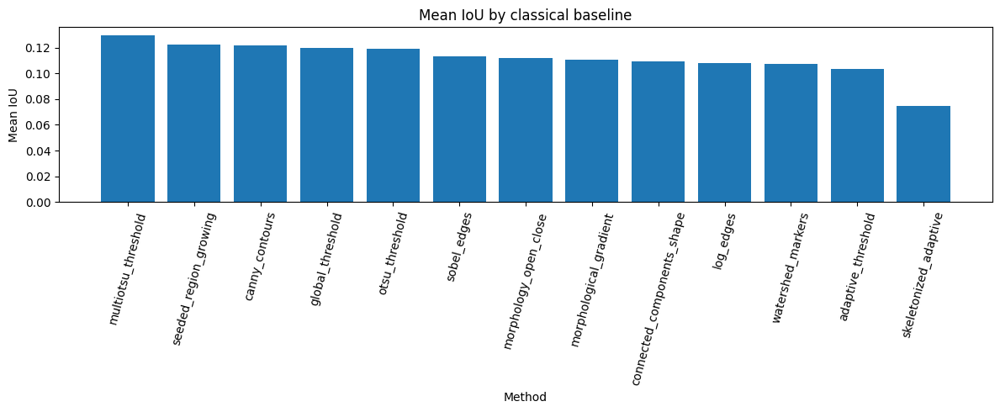

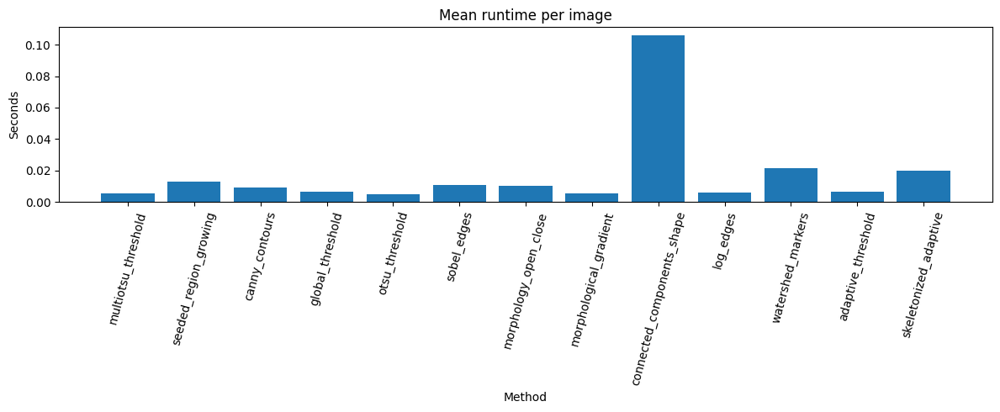

Best classical baseline by mean IoU: multiotsu_threshold


In [12]:
if len(comparison_table) > 0:
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.bar(comparison_table["method"], comparison_table["mean_iou"])
    ax.set_title("Mean IoU by classical baseline")
    ax.set_ylabel("Mean IoU")
    ax.set_xlabel("Method")
    ax.tick_params(axis="x", rotation=75)
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.bar(comparison_table["method"], comparison_table["mean_runtime_sec"])
    ax.set_title("Mean runtime per image")
    ax.set_ylabel("Seconds")
    ax.set_xlabel("Method")
    ax.tick_params(axis="x", rotation=75)
    plt.tight_layout()
    plt.show()

    best_method = comparison_table.iloc[0]["method"]
    print(f"Best classical baseline by mean IoU: {best_method}")
else:
    best_method = "adaptive_threshold"
    print(f"No comparison table available. Default selected baseline: {best_method}")

## 13. Best baseline qualitative review

The selected method is reviewed using prediction overlays, boundary overlays, and error overlays.

Reviewing best method:   0%|          | 0/5 [00:00<?, ?image/s]

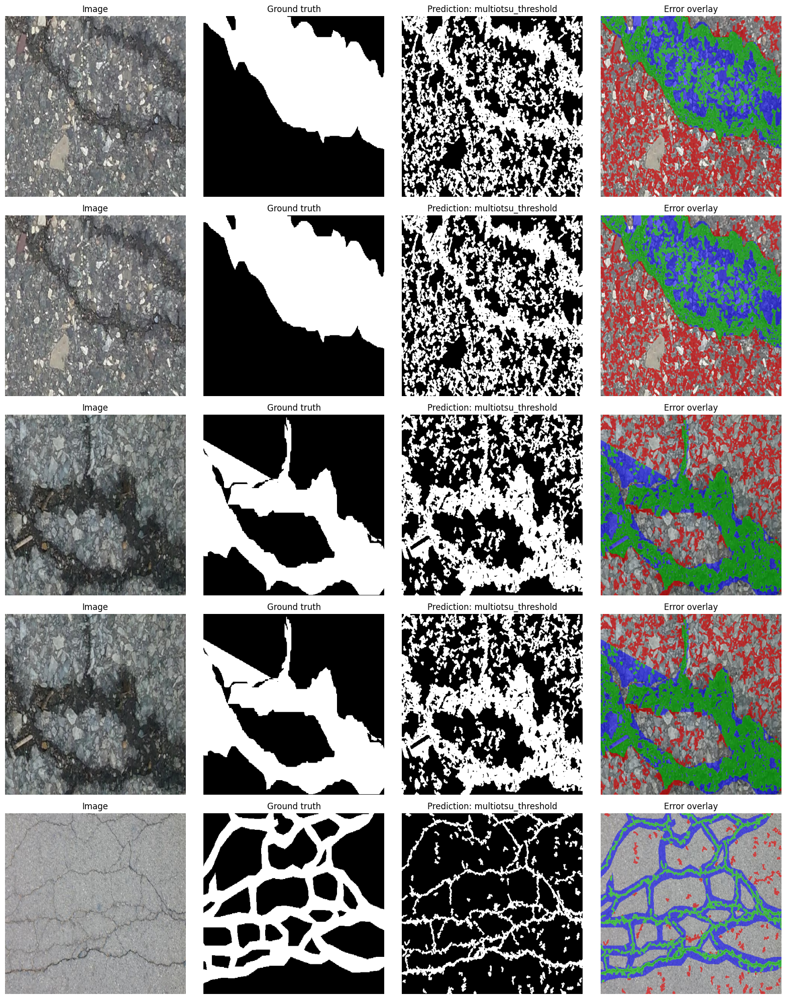

In [13]:
def plot_best_method_review(df_source, method_name, max_samples=5):
    method_fn = BASELINES[method_name]

    if "foreground_ratio" in df_source.columns:
        source = df_source.sort_values("foreground_ratio", ascending=False).head(max_samples)
    else:
        source = df_source.head(max_samples)

    fig, axes = plt.subplots(len(source), 4, figsize=(16, 4 * len(source)))
    if len(source) == 1:
        axes = np.expand_dims(axes, axis=0)

    # Review selected samples using the best method identified in the quantitative table.
    for i, (_, row) in enumerate(show_progress(source.iterrows(), total=len(source), desc="Reviewing best method", unit="image")):
        rgb = read_rgb(row["image_path"])
        gray = rgb_to_gray(rgb)
        gt = read_mask(row["mask_path"], target_shape=gray.shape) if row["mask_path"] else None
        pred = method_fn(rgb)
        pred = ensure_same_shape(pred, gray.shape)

        axes[i, 0].imshow(rgb)
        axes[i, 0].set_title("Image")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(gt if gt is not None else np.zeros_like(gray), cmap="gray")
        axes[i, 1].set_title("Ground truth")
        axes[i, 1].axis("off")

        axes[i, 2].imshow(pred, cmap="gray")
        axes[i, 2].set_title(f"Prediction: {method_name}")
        axes[i, 2].axis("off")

        if gt is not None:
            axes[i, 3].imshow(error_overlay(rgb, gt, pred))
            axes[i, 3].set_title("Error overlay")
        else:
            axes[i, 3].imshow(make_overlay(rgb, pred))
            axes[i, 3].set_title("Prediction overlay")
        axes[i, 3].axis("off")

    plt.tight_layout()
    plt.show()


if len(paired_df) > 0:
    plot_best_method_review(paired_df, best_method, max_samples=5)
else:
    print("Best-method review with ground truth is skipped because masks were not found.")

## 14. Failure-case analysis

This section identifies three common failure categories:

1. **Weak crack cases:** low Dice score on images with very small or faint crack regions.
2. **Noisy surface cases:** high false-positive prediction when the ground-truth foreground is absent or very small.
3. **Noncrack or near-noncrack cases:** images with empty or almost-empty masks.

The selected baseline is used for this diagnostic analysis.

,failure_type,image_name,iou,dice,precision,recall,gt_foreground_ratio,pred_foreground_ratio
0,weak_crack_or_undersegmentation,cracktree200_6212.jpg,0.007888,0.015652,0.007889,0.982343,0.003104,0.386524
1,weak_crack_or_undersegmentation,Rissbilder_for_Florian_9S6A2843_0_0_3840_5760.jpg,0.013550,0.026737,0.014915,0.128946,0.011206,0.096879
2,weak_crack_or_undersegmentation,GAPS384_train_1181_541_1.jpg,0.019145,0.037570,0.019153,0.978305,0.009875,0.504419
3,weak_crack_or_undersegmentation,Rissbilder_for_Florian_9S6A3097_236_1472_3435_3344.jpg,0.024106,0.047077,0.024457,0.626463,0.014046,0.359769
4,weak_crack_or_undersegmentation,CRACK500_20160407_165009_1_721.jpg,0.026106,0.050885,0.026286,0.792441,0.015291,0.460977
5,noisy_surface_or_false_positive,noncrack_noncrack_concrete_wall_74_19.jpg.jpg,0.000000,0.000000,0.000000,1.000000,0.000000,0.331777
6,noisy_surface_or_false_positive,noncrack_noncrack_concrete_wall_11_0.jpg.jpg,0.000000,0.000000,0.000000,1.000000,0.000000,0.314837
7,noisy_surface_or_false_positive,noncrack_noncrack_concrete_wall_74_15.jpg.jpg,0.000000,0.000000,0.000000,1.000000,0.000000,0.306501
8,noisy_surface_or_false_positive,noncrack_noncrack_concrete_wall_18_14.jpg.jpg,0.000000,0.000000,0.000000,1.000000,0.000000,0.241709
9,noisy_surface_or_false_positive,noncrack_noncrack_concrete_wall_41_38.jpg.jpg,0.000000,0.000000,0.000000,1.000000,0.000000,0.219871


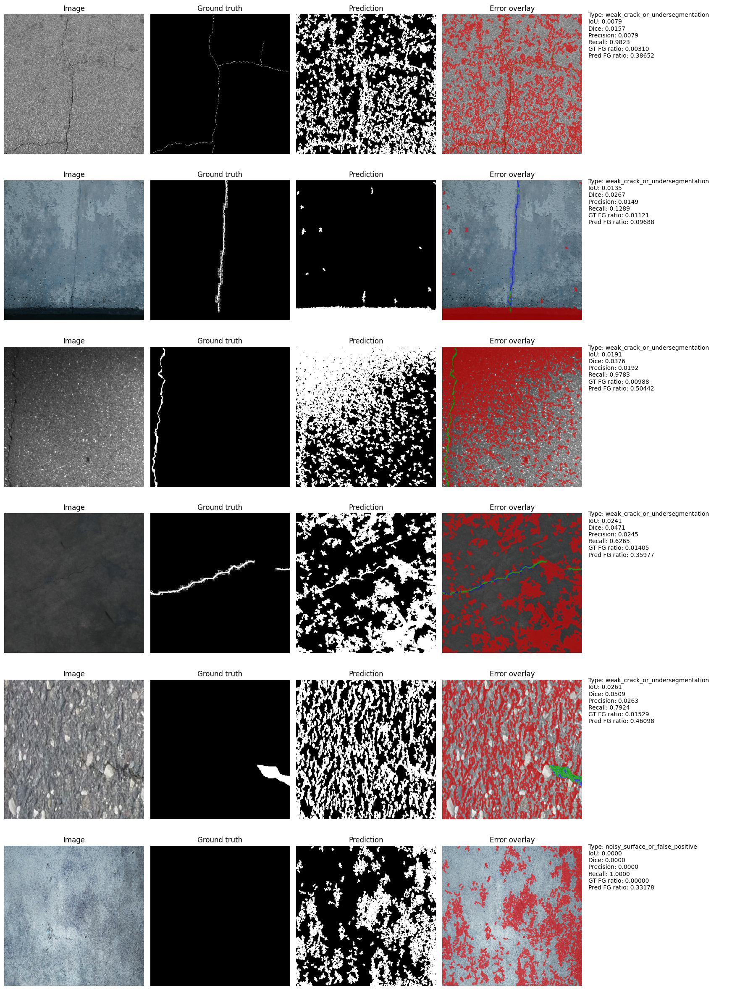

In [14]:
def failure_case_table(metrics_df, method_name):
    if len(metrics_df) == 0:
        return pd.DataFrame()

    mdf = metrics_df[metrics_df["method"] == method_name].copy()

    weak = (
        mdf[mdf["gt_foreground_ratio"] > 0]
        .sort_values(["dice", "gt_foreground_ratio"], ascending=[True, True])
        .head(5)
        .assign(failure_type="weak_crack_or_undersegmentation")
    )

    noisy = (
        mdf[mdf["gt_foreground_ratio"] <= 0.002]
        .sort_values("pred_foreground_ratio", ascending=False)
        .head(5)
        .assign(failure_type="noisy_surface_or_false_positive")
    )

    noncrack = (
        mdf[mdf["gt_foreground_ratio"] == 0]
        .sort_values("pred_foreground_ratio", ascending=False)
        .head(5)
        .assign(failure_type="noncrack_case")
    )

    cases = pd.concat([weak, noisy, noncrack], ignore_index=True)
    cases = cases.drop_duplicates(subset=["image_path", "failure_type"])
    return cases


def plot_failure_cases(cases, method_name, max_cases=6):
    if len(cases) == 0:
        print("No failure cases found for this selection.")
        return

    method_fn = BASELINES[method_name]
    cases = cases.head(max_cases)

    fig, axes = plt.subplots(len(cases), 5, figsize=(18, 4 * len(cases)))
    if len(cases) == 1:
        axes = np.expand_dims(axes, axis=0)

    for i, (_, row) in enumerate(cases.iterrows()):
        rgb = read_rgb(row["image_path"])
        gray = rgb_to_gray(rgb)
        gt = read_mask(row["mask_path"], target_shape=gray.shape)
        pred = ensure_same_shape(method_fn(rgb), gt.shape)

        axes[i, 0].imshow(rgb)
        axes[i, 0].set_title("Image")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(gt, cmap="gray")
        axes[i, 1].set_title("Ground truth")
        axes[i, 1].axis("off")

        axes[i, 2].imshow(pred, cmap="gray")
        axes[i, 2].set_title("Prediction")
        axes[i, 2].axis("off")

        axes[i, 3].imshow(error_overlay(rgb, gt, pred))
        axes[i, 3].set_title("Error overlay")
        axes[i, 3].axis("off")

        axes[i, 4].axis("off")
        text = (
            f"Type: {row['failure_type']}\n"
            f"IoU: {row['iou']:.4f}\n"
            f"Dice: {row['dice']:.4f}\n"
            f"Precision: {row['precision']:.4f}\n"
            f"Recall: {row['recall']:.4f}\n"
            f"GT FG ratio: {row['gt_foreground_ratio']:.5f}\n"
            f"Pred FG ratio: {row['pred_foreground_ratio']:.5f}"
        )
        axes[i, 4].text(0, 0.95, text, va="top", fontsize=10)

    plt.tight_layout()
    plt.show()


if len(metrics_df) > 0:
    cases = failure_case_table(metrics_df, best_method)
    display(cases[[
        "failure_type", "image_name", "iou", "dice", "precision", "recall",
        "gt_foreground_ratio", "pred_foreground_ratio"
    ]].head(15))
    plot_failure_cases(cases, best_method, max_cases=6)
else:
    print("Failure-case analysis skipped because no evaluation metrics are available.")

## 15. Batch-create binary masks from images

This section creates pseudo-masks from image folders using the selected classical baseline.  
It works even when no ground-truth masks are available.

Generated outputs:

```text
/kaggle/working/seg01_generated_masks
/kaggle/working/seg01_generated_overlays
/kaggle/working/seg01_generated_mask_index.csv
/kaggle/working/seg01_generated_masks.zip
```

Use this section carefully. Classical pseudo-masks are useful for weak supervision, bootstrapping, and classroom comparison, but they are not replacements for verified annotations.

In [15]:
def save_binary_mask(mask, output_path):
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    cv2.imwrite(str(output_path), (mask.astype(np.uint8) * 255))


def save_overlay(rgb, mask, output_path):
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    overlay = make_overlay(rgb, mask, color=(255, 0, 0), alpha=0.45)
    overlay_bgr = cv2.cvtColor(overlay, cv2.COLOR_RGB2BGR)
    cv2.imwrite(str(output_path), overlay_bgr)


def batch_create_masks(
    image_paths,
    method_name=None,
    mask_dir=None,
    overlay_dir=None,
    limit=None
):
    if method_name is None:
        method_name = best_method if "best_method" in globals() else "adaptive_threshold"

    if method_name not in BASELINES:
        raise ValueError(f"Unknown method: {method_name}. Available methods: {list(BASELINES.keys())}")

    if mask_dir is None:
        mask_dir = CONFIG["generated_mask_dir"]
    if overlay_dir is None:
        overlay_dir = CONFIG["overlay_dir"]

    mask_dir = Path(mask_dir)
    overlay_dir = Path(overlay_dir)
    mask_dir.mkdir(parents=True, exist_ok=True)
    overlay_dir.mkdir(parents=True, exist_ok=True)

    method_fn = BASELINES[method_name]
    image_paths = [Path(p) for p in image_paths]
    if limit is not None:
        image_paths = image_paths[:limit]

    records = []
    start_all = time.perf_counter()

    # Each image is segmented, saved as a binary mask, and paired with an overlay for inspection.
    for i, image_path in enumerate(show_progress(image_paths, desc="Generating masks", total=len(image_paths), unit="image")):
        rgb = read_rgb(image_path)
        pred = method_fn(rgb)
        pred = ensure_same_shape(pred, rgb.shape[:2])

        rel_name = f"{image_path.stem}_{method_name}_mask.png"
        overlay_name = f"{image_path.stem}_{method_name}_overlay.png"

        mask_out = mask_dir / rel_name
        overlay_out = overlay_dir / overlay_name

        save_binary_mask(pred, mask_out)
        save_overlay(rgb, pred, overlay_out)

        records.append({
            "image_path": str(image_path),
            "generated_mask_path": str(mask_out),
            "generated_overlay_path": str(overlay_out),
            "method": method_name,
            "pred_foreground_ratio": float(pred.mean()),
            "height": int(pred.shape[0]),
            "width": int(pred.shape[1]),
        })

        if (i + 1) % 50 == 0 or (i + 1) == len(image_paths):
            print(f"Generated {i + 1}/{len(image_paths)} masks")

    elapsed = time.perf_counter() - start_all
    index_df = pd.DataFrame(records)
    index_path = "/kaggle/working/seg01_generated_mask_index.csv"
    index_df.to_csv(index_path, index=False)

    print(f"Finished batch mask generation in {elapsed:.2f} seconds")
    print(f"Mask directory: {mask_dir}")
    print(f"Overlay directory: {overlay_dir}")
    print(f"Index CSV: {index_path}")

    return index_df


all_image_paths = df_pairs["image_path"].tolist()

# Set limit=None for the full dataset.
# During initial testing, use a small limit such as 20.
generated_index_df = batch_create_masks(
    all_image_paths,
    method_name=best_method,
    limit=20
)

display(generated_index_df.head())

Generating masks:   0%|          | 0/20 [00:00<?, ?image/s]

Generated 20/20 masks
Finished batch mask generation in 0.58 seconds
Mask directory: /kaggle/working/seg01_generated_masks
Overlay directory: /kaggle/working/seg01_generated_overlays
Index CSV: /kaggle/working/seg01_generated_mask_index.csv


,image_path,generated_mask_path,generated_overlay_path,method,pred_foreground_ratio,height,width
0,/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/test/images/CFD_001.jpg,/kaggle/working/seg01_generated_masks/CFD_001_multiotsu_threshold_mask.png,/kaggle/working/seg01_generated_overlays/CFD_001_multiotsu_threshold_overlay.png,multiotsu_threshold,0.192293,448,448
1,/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/test/images/CFD_007.jpg,/kaggle/working/seg01_generated_masks/CFD_007_multiotsu_threshold_mask.png,/kaggle/working/seg01_generated_overlays/CFD_007_multiotsu_threshold_overlay.png,multiotsu_threshold,0.159852,448,448
2,/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/test/images/CFD_011.jpg,/kaggle/working/seg01_generated_masks/CFD_011_multiotsu_threshold_mask.png,/kaggle/working/seg01_generated_overlays/CFD_011_multiotsu_threshold_overlay.png,multiotsu_threshold,0.260538,448,448
3,/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/test/images/CFD_013.jpg,/kaggle/working/seg01_generated_masks/CFD_013_multiotsu_threshold_mask.png,/kaggle/working/seg01_generated_overlays/CFD_013_multiotsu_threshold_overlay.png,multiotsu_threshold,0.306367,448,448
4,/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/test/images/CFD_014.jpg,/kaggle/working/seg01_generated_masks/CFD_014_multiotsu_threshold_mask.png,/kaggle/working/seg01_generated_overlays/CFD_014_multiotsu_threshold_overlay.png,multiotsu_threshold,0.232387,448,448


## 16. Preview generated masks

The preview confirms that the batch mask creation process is saving masks and overlays correctly.

Previewing generated masks:   0%|          | 0/6 [00:00<?, ?mask/s]

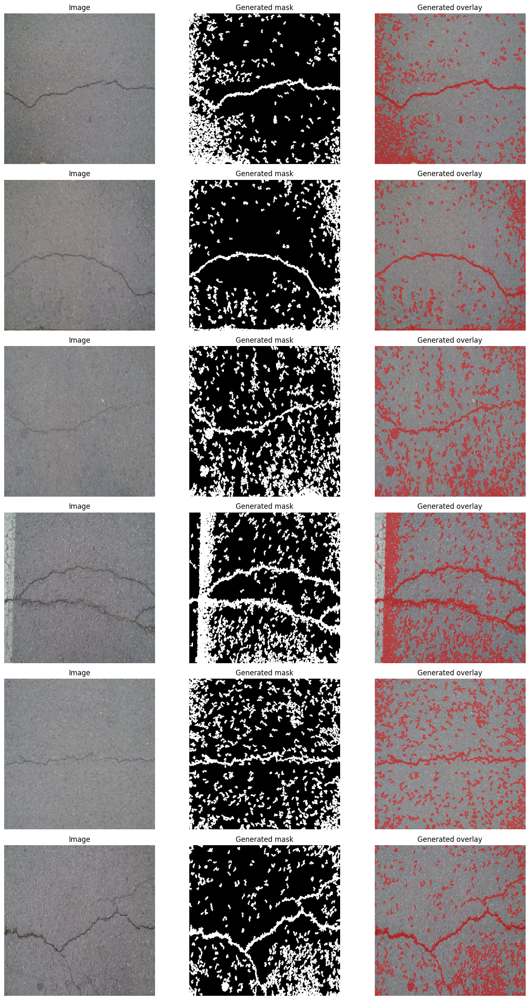

In [16]:
def preview_generated_masks(index_df, max_items=6):
    if len(index_df) == 0:
        print("No generated masks to preview.")
        return

    sample = index_df.head(max_items)
    fig, axes = plt.subplots(len(sample), 3, figsize=(14, 4 * len(sample)))
    if len(sample) == 1:
        axes = np.expand_dims(axes, axis=0)

    # Load generated masks from disk to verify that the batch step saved valid files.
    for i, (_, row) in enumerate(show_progress(sample.iterrows(), total=len(sample), desc="Previewing generated masks", leave=False, unit="mask")):
        rgb = read_rgb(row["image_path"])
        mask = read_gray(row["generated_mask_path"]) > 127
        overlay = read_rgb(row["generated_overlay_path"])

        axes[i, 0].imshow(rgb)
        axes[i, 0].set_title("Image")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(mask, cmap="gray")
        axes[i, 1].set_title("Generated mask")
        axes[i, 1].axis("off")

        axes[i, 2].imshow(overlay)
        axes[i, 2].set_title("Generated overlay")
        axes[i, 2].axis("off")

    plt.tight_layout()
    plt.show()


preview_generated_masks(generated_index_df, max_items=6)

## 17. Export generated masks as a ZIP file

After inspecting the output quality, set `limit=None` in the batch mask generation cell and rerun it for the full dataset.  
The cell below compresses the generated masks for download from Kaggle.

In [17]:
import shutil

mask_dir = Path(CONFIG["generated_mask_dir"])
zip_base = "/kaggle/working/seg01_generated_masks"
zip_path = f"{zip_base}.zip"

if mask_dir.exists():
    if Path(zip_path).exists():
        Path(zip_path).unlink()
    shutil.make_archive(zip_base, "zip", root_dir=str(mask_dir))
    print(f"ZIP created: {zip_path}")
else:
    print("Mask directory does not exist yet. Run the batch mask generation section first.")

ZIP created: /kaggle/working/seg01_generated_masks.zip


## 18. Final interpretation guide

Use the comparison table to select the best classical segmentation baseline.  
For crack segmentation, a useful method should not be judged by IoU alone. It should also be inspected visually because thin cracks occupy a very small fraction of the image area.

Suggested interpretation:

1. **High recall with low precision** means the method detects many cracks but also marks texture, shadows, or noise as crack.
2. **High precision with low recall** means the method is conservative and misses weak or hairline cracks.
3. **Good Dice but weak boundary overlay** means the foreground area may overlap, but the crack shape is not well localized.
4. **Strong performance on noncrack images** is necessary because the background class dominates the dataset.
5. **Fast runtime** matters when the method is used as a pseudo-mask generator for a large image folder.

For this module, the selected classical baseline should be treated as a reproducible reference method. Deep learning models can later be compared against this baseline using the same images, masks, and metrics.